# Statistiques computationnelles pour le Big Data — chapitre 4

> Aly DIALLO — codes Python

Régression logistique bayésienne sur le jeu de données Adult (UCI). Les fonctions de recombinaison par lots et les divergences KL sont identiques à celles du notebook des chapitres 1 à 3. Les figures 4.1 à 4.5 sont enregistrées dans `Figures/`.

Dépendances : `numpy`, `scipy`, `matplotlib`, `numba`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

## Code commun aux chapitres 3 et 4

Les fonctions ci-dessous (recombinaisons par lots du chapitre 1 et divergence KL) sont **identiques** dans les deux notebooks.

- `consensus_scott` : Algorithme 1 et éq. (1.18), poids $W_s = \widehat{\mathrm{Var}}(\theta_s)^{-1}$ (covariance complète par défaut).
- `neiswanger_parametric` : produit de gaussiennes, éq. (1.17).
- `neiswanger_nonparametric` : Algorithme 2 (Metropolis-within-Gibbs sur les étiquettes $\mathbf L$), poids $\omega_{\mathbf L}$ de l'éq. (1.22), tirage $\theta \sim \mathcal N(\bar\theta_{\mathbf L}, h^2/S\, I)$.
- `neiswanger_semiparametric` : poids $\omega_{\mathbf L}$, composante $\mathcal N(\mu_{\mathbf L}, \Sigma_{\mathbf L})$ de l'éq. (1.25).
- `neiswanger_semiparametric_full` : poids exacts $W_{\mathbf L}$ de l'éq. (1.26), composante (1.25).

Avec recuit, la fenêtre suit $h(j) = h_0\, j^{-1/(4+d)}$ et le poids de l'étiquette courante est recalculé sous $h(j)$ à chaque itération.

**Divergence KL.** Les échantillons MCMC étant autocorrélés, l'estimateur k-NN (conçu pour des tirages i.i.d.) est appliqué après amincissement de chaque échantillon d'un pas égal à son temps d'autocorrélation intégré $\tau$ (`kl_mcmc`). En dimension $d \gtrsim 5$, l'estimateur k-NN devient fortement biaisé (une loi sur-dispersée y reçoit une KL négative) ; on utilise alors la KL entre approximations gaussiennes (`kl_gauss`), justifiée par le théorème de Bernstein-von Mises.

Le code utilise `numba` pour accélérer les boucles (`pip install numba`). Sans `numba`, il s'exécute à l'identique mais beaucoup plus lentement.

In [2]:
# =====================================================================
#  CODE COMMUN AUX CHAPITRES 3 ET 4
#  (recombinaisons par lots du chapitre 1 + estimateur KL k-NN)
#  Ce bloc est STRICTEMENT IDENTIQUE dans les deux notebooks.
# =====================================================================
import numpy as np
from scipy.spatial import cKDTree

try:
    from numba import njit
    NUMBA_OK = True
except ImportError:                     # repli : même code, exécuté en Python pur (lent)
    NUMBA_OK = False
    def njit(*args, **kwargs):
        if len(args) == 1 and callable(args[0]):
            return args[0]
        return lambda f: f

In [3]:
# ---------------------------------------------------------------------
#  Estimateur k-NN de la divergence KL et amincissement des chaînes

In [4]:
# ---------------------------------------------------------------------
def kl_knn(samples_p, samples_q, k=1):
    """KL(P||Q) par k plus proches voisins (Wang, Kulkarni & Verdú, 2009) :
    KL ≈ (d/n) Σ log(ν_k/ρ_k) + log(m/(n-1)).  Suppose des tirages i.i.d."""
    P = np.asarray(samples_p, float)
    Q = np.asarray(samples_q, float)
    if P.ndim == 1:
        P = P[:, None]
    if Q.ndim == 1:
        Q = Q[:, None]
    n, d = P.shape
    m = Q.shape[0]
    rho = cKDTree(P).query(P, k=k + 1)[0][:, k]
    nu = cKDTree(Q).query(P, k=k)[0]
    nu = nu if k == 1 else nu[:, k - 1]
    rho = np.maximum(rho, 1e-300)
    nu = np.maximum(nu, 1e-300)
    return float((d / n) * np.sum(np.log(nu / rho)) + np.log(m / (n - 1)))


def integrated_autocorr_time(x, c=5.0):
    """Temps d'autocorrélation intégré τ (fenêtre automatique de Sokal),
    maximum sur les coordonnées. τ ≈ 1 pour des tirages indépendants."""
    x = np.asarray(x, float)
    if x.ndim == 1:
        x = x[:, None]
    n = x.shape[0]
    if n < 20:
        return 1.0
    xc = x - x.mean(axis=0)
    nfft = 1 << (2 * n - 1).bit_length()
    f = np.fft.rfft(xc, n=nfft, axis=0)
    acf = np.fft.irfft(f * np.conj(f), n=nfft, axis=0)[:n]
    var0 = acf[0]
    ok = var0 > 0
    if not np.any(ok):
        return float(n)               # chaîne figée
    rho = acf[:, ok] / var0[ok]
    taus = 2.0 * np.cumsum(rho, axis=0) - 1.0
    tau_max = 1.0
    for j in range(taus.shape[1]):
        win = np.arange(n) >= c * taus[:, j]
        w = int(np.argmax(win)) if np.any(win) else n - 1
        tau_max = max(tau_max, float(taus[w, j]))
    return tau_max


def thin_chain(x, n_min=200):
    """Amincit un échantillon MCMC d'un pas ⌈τ⌉ (≈ ESS points quasi indépendants),
    en conservant au moins n_min points régulièrement espacés."""
    x = np.asarray(x, float)
    step = max(1, int(np.ceil(integrated_autocorr_time(x))))
    step = min(step, max(1, x.shape[0] // n_min))
    return x[::step]


def kl_mcmc(samples_p, samples_q, n_max=2000, rng=None):
    """KL k-NN adaptée aux sorties MCMC : chaque échantillon est aminci à des
    tirages quasi indépendants (au moins 200 points), puis ramené à au plus n_max points.
    Sans cet amincissement, le plus proche voisin d'un point est son prédécesseur
    dans la chaîne et la KL est artificiellement gonflée. Si la taille effective
    est inférieure à 200, la corrélation résiduelle pénalise la chaîne (mélange lent).
    Les points identiques de P (rejets MH simultanés) sont retirés : ils donneraient
    ρ_k = 0 et une KL infinie."""
    if rng is None:
        rng = np.random.default_rng(0)
    P = np.unique(thin_chain(samples_p), axis=0)   # points identiques (rejets MH) : ρ = 0
    Q = thin_chain(samples_q)
    if P.shape[0] > n_max:
        P = P[rng.choice(P.shape[0], n_max, replace=False)]
    if Q.shape[0] > n_max:
        Q = Q[rng.choice(Q.shape[0], n_max, replace=False)]
    return kl_knn(P, Q)


def kl_gauss(samples_p, samples_q):
    """KL entre les approximations gaussiennes des deux échantillons :
    KL(N(μ_P,Σ_P) || N(μ_Q,Σ_Q)) = ½[tr(Σ_Q⁻¹Σ_P) + (μ_Q-μ_P)ᵀΣ_Q⁻¹(μ_Q-μ_P) - d + log|Σ_Q|/|Σ_P|].
    Utilise tous les points (moyenne et covariance restent consistantes pour une chaîne
    autocorrélée). À privilégier dès d ≳ 5, où l'estimateur k-NN devient fortement biaisé
    (une loi sur-dispersée y reçoit une KL estimée négative)."""
    P = np.asarray(samples_p, float)
    Q = np.asarray(samples_q, float)
    if P.ndim == 1:
        P = P[:, None]
    if Q.ndim == 1:
        Q = Q[:, None]
    d = P.shape[1]
    mp, mq = P.mean(axis=0), Q.mean(axis=0)
    Sp = np.atleast_2d(np.cov(P, rowvar=False))
    Sq = np.atleast_2d(np.cov(Q, rowvar=False))
    iq = np.linalg.inv(Sq)
    dm = mq - mp
    return float(0.5 * (np.trace(iq @ Sp) + dm @ iq @ dm - d
                        + np.linalg.slogdet(Sq)[1] - np.linalg.slogdet(Sp)[1]))

In [5]:
# ---------------------------------------------------------------------
#  Méthodes paramétriques (section 1.4)

In [6]:
# ---------------------------------------------------------------------
def _batch_moments(batch_samples):
    """Moyennes μ̂_s, covariances Σ̂_s et précisions Σ̂_s^{-1} empiriques de chaque lot."""
    S = len(batch_samples)
    d = batch_samples[0].shape[1]
    mu = np.empty((S, d))
    cov = np.empty((S, d, d))
    prec = np.empty((S, d, d))
    for s in range(S):
        mu[s] = batch_samples[s].mean(axis=0)
        cov[s] = np.atleast_2d(np.cov(batch_samples[s], rowvar=False))
        prec[s] = np.linalg.pinv(cov[s])
    return mu, cov, prec


def parametric_product(batch_samples):
    """Produit des approximations gaussiennes (éq. 1.17) :
    Σ̂ = (Σ_s Σ̂_s^{-1})^{-1},  μ̂ = Σ̂ Σ_s Σ̂_s^{-1} μ̂_s.  Renvoie (μ̂, Σ̂, Σ̂^{-1})."""
    mu, cov, prec = _batch_moments(batch_samples)
    prec_tot = prec.sum(axis=0)
    sigma = np.linalg.pinv(prec_tot)
    sigma = 0.5 * (sigma + sigma.T)
    mu_hat = sigma @ np.einsum("sij,sj->i", prec, mu)
    return mu_hat, sigma, prec_tot


def consensus_scott(batch_samples, diagonal=False):
    """Consensus Monte Carlo (Algorithme 1, éq. 1.18) :
    θ̂_j = (Σ_s W_s)^{-1} Σ_s W_s θ_{s,j},  W_s = Var(θ_s)^{-1}.
    diagonal=False : W_s = inverse de la covariance empirique complète du lot ;
    diagonal=True  : W_s = inverse des seules variances marginales."""
    stacked = np.stack(batch_samples, axis=0)                # (S, M, d)
    if diagonal:
        w = 1.0 / np.maximum(stacked.var(axis=1, ddof=1), 1e-300)   # (S, d)
        return np.einsum("sd,smd->md", w, stacked) / w.sum(axis=0)
    _, _, prec = _batch_moments(batch_samples)
    num = np.einsum("sij,smj->mi", prec, stacked)
    return num @ np.linalg.pinv(prec.sum(axis=0)).T


def neiswanger_parametric(batch_samples, n_samples=None, rng=None):
    """Méthode paramétrique de Neiswanger : tirages i.i.d. de N(μ̂, Σ̂) (éq. 1.17)."""
    if rng is None:
        rng = np.random.default_rng()
    n_samples = n_samples or batch_samples[0].shape[0]
    mu_hat, sigma, _ = parametric_product(batch_samples)
    return rng.multivariate_normal(mu_hat, sigma, size=n_samples)

In [7]:
# ---------------------------------------------------------------------
#  Metropolis-within-Gibbs sur les étiquettes L (Algorithme 2)

In [8]:
# ---------------------------------------------------------------------
@njit
def _mwg_labels(samples, sqn, h_seq, cand, logu, labels0, full, logf, mu_hat, V, sig_eig):
    """Échantillonne les étiquettes L = (l_1..l_S) du mélange à M^S composantes.

    Poids non paramétrique (éq. 1.22), à une constante dépendant de h près :
        log ω_L = -(1/2h²) Σ_s ||θ_{l_s,s} - θ̄_L||²
                = -(1/2h²) (Σ_s ||θ_{l_s,s}||² - S ||θ̄_L||²).
    Poids semi-paramétrique complet (éq. 1.26) si full=True :
        log W_L = log ω_L + log N(θ̄_L | μ̂, Σ̂ + h²/S I) - Σ_s log f̂_s(θ_{l_s,s}).
    À chaque itération j, le poids courant est recalculé sous la fenêtre h(j),
    de sorte que le rapport ω_C/ω_L compare deux poids sous la même fenêtre."""
    S, M, d = samples.shape
    T = h_seq.shape[0]
    tbar_out = np.empty((T, d))
    labels = labels0.copy()
    ssum = np.zeros(d)
    newsum = np.zeros(d)
    n_acc = 0
    for j in range(T):
        h2 = h_seq[j] * h_seq[j]
        hs = h2 / S
        # sommes exactes pour l'étiquette courante
        for k in range(d):
            ssum[k] = 0.0
        ssq = 0.0
        slf = 0.0
        for s in range(S):
            l = labels[s]
            ssq += sqn[s, l]
            slf += logf[s, l]
            for k in range(d):
                ssum[k] += samples[s, l, k]
        # log-poids courant sous h(j)
        nrm = 0.0
        for k in range(d):
            nrm += ssum[k] * ssum[k]
        cur = -(ssq - nrm / S) / (2.0 * h2)
        if full:
            q = 0.0
            for a in range(d):
                z = 0.0
                for k in range(d):
                    z += V[k, a] * (ssum[k] / S - mu_hat[k])
                q += z * z / (sig_eig[a] + hs)
            cur += -0.5 * q - slf
        for s in range(S):
            c = cand[j, s]
            old = labels[s]
            if c == old:
                continue
            nssq = ssq - sqn[s, old] + sqn[s, c]
            nrm = 0.0
            for k in range(d):
                newsum[k] = ssum[k] - samples[s, old, k] + samples[s, c, k]
                nrm += newsum[k] * newsum[k]
            lw = -(nssq - nrm / S) / (2.0 * h2)
            nslf = slf - logf[s, old] + logf[s, c]
            if full:
                q = 0.0
                for a in range(d):
                    z = 0.0
                    for k in range(d):
                        z += V[k, a] * (newsum[k] / S - mu_hat[k])
                    q += z * z / (sig_eig[a] + hs)
                lw += -0.5 * q - nslf
            if logu[j, s] < lw - cur:
                labels[s] = c
                ssq = nssq
                slf = nslf
                for k in range(d):
                    ssum[k] = newsum[k]
                cur = lw
                n_acc += 1
        for k in range(d):
            tbar_out[j, k] = ssum[k] / S
    return tbar_out, n_acc


def _run_label_sampler(batch_samples, bandwidth, anneal, n_samples, rng, full):
    stacked = np.ascontiguousarray(np.stack(batch_samples, axis=0), dtype=float)   # (S, M, d)
    S, M, d = stacked.shape
    T = n_samples or M
    h0 = float(bandwidth)
    j = np.arange(1, T + 1, dtype=float)
    h_seq = h0 * j ** (-1.0 / (4.0 + d)) if anneal else np.full(T, h0)   # recuit h(j)
    sqn = np.einsum("smd,smd->sm", stacked, stacked)
    cand = rng.integers(0, M, size=(T, S))
    logu = np.log(rng.uniform(size=(T, S)))
    labels0 = rng.integers(0, M, size=S)
    mu_hat, sigma, prec_tot = parametric_product(batch_samples)
    if full:
        mu_b, cov_b, prec_b = _batch_moments(batch_samples)
        logf = np.empty((S, M))
        for s in range(S):                                   # log f̂_s(θ_{m,s})
            diff = stacked[s] - mu_b[s]
            sign, logdet = np.linalg.slogdet(cov_b[s])
            logf[s] = -0.5 * np.einsum("mi,ij,mj->m", diff, prec_b[s], diff) - 0.5 * logdet
        sig_eig, V = np.linalg.eigh(sigma)
        sig_eig = np.maximum(sig_eig, 1e-300)
    else:
        logf = np.zeros((S, M))
        sig_eig, V = np.ones(d), np.eye(d)
    tbar, n_acc = _mwg_labels(stacked, sqn, h_seq, cand, logu, labels0, bool(full),
                              logf, mu_hat, V, sig_eig)
    return tbar, h_seq, mu_hat, prec_tot, n_acc / (T * S)


def neiswanger_nonparametric(batch_samples, bandwidth, anneal=True, n_samples=None,
                             rng=None, return_acc=False):
    """Méthode non paramétrique (Algorithme 2) : θ_j ~ N(θ̄_L, h(j)²/S · I)."""
    if rng is None:
        rng = np.random.default_rng()
    tbar, h_seq, _, _, acc = _run_label_sampler(batch_samples, bandwidth, anneal,
                                                n_samples, rng, full=False)
    S = len(batch_samples)
    out = tbar + (h_seq / np.sqrt(S))[:, None] * rng.standard_normal(tbar.shape)
    return (out, acc) if return_acc else out


def _semipara_draw(tbar, h_seq, mu_hat, prec_tot, S, rng):
    """Composante (éq. 1.25) : Σ_L = (S/h² I + Σ̂^{-1})^{-1},
    μ_L = Σ_L (S/h² θ̄_L + Σ̂^{-1} μ̂) ; tirage θ_j ~ N(μ_L, Σ_L)."""
    lam, U = np.linalg.eigh(0.5 * (prec_tot + prec_tot.T))
    lam = np.maximum(lam, 0.0)
    kappa = S / h_seq ** 2                                      # (T,)
    inv_eig = 1.0 / (kappa[:, None] + lam[None, :])             # (T, d)
    rhs = kappa[:, None] * tbar + (prec_tot @ mu_hat)[None, :]
    mean = ((rhs @ U) * inv_eig) @ U.T
    noise = (rng.standard_normal(tbar.shape) * np.sqrt(inv_eig)) @ U.T
    return mean + noise


def neiswanger_semiparametric(batch_samples, bandwidth, anneal=True, n_samples=None,
                              rng=None, return_acc=False):
    """Semi-paramétrique (heuristique) : poids non paramétriques ω_L, composante (1.25)."""
    if rng is None:
        rng = np.random.default_rng()
    tbar, h_seq, mu_hat, prec_tot, acc = _run_label_sampler(batch_samples, bandwidth,
                                                            anneal, n_samples, rng, full=False)
    out = _semipara_draw(tbar, h_seq, mu_hat, prec_tot, len(batch_samples), rng)
    return (out, acc) if return_acc else out


def neiswanger_semiparametric_full(batch_samples, bandwidth, anneal=True, n_samples=None,
                                   rng=None, return_acc=False):
    """Semi-paramétrique complet : poids exacts W_L (éq. 1.26), composante (1.25)."""
    if rng is None:
        rng = np.random.default_rng()
    tbar, h_seq, mu_hat, prec_tot, acc = _run_label_sampler(batch_samples, bandwidth,
                                                            anneal, n_samples, rng, full=True)
    out = _semipara_draw(tbar, h_seq, mu_hat, prec_tot, len(batch_samples), rng)
    return (out, acc) if return_acc else out

## Modèle logistique (section 4.2) et échantillonneurs

- Log-posteriori (4.4), gradient (4.5), estimateur stochastique (4.6), Hessienne analytique (4.7).
- MH de référence : pendant le burn-in, échelle adaptée (cible 25 %) et, à partir de 1000 itérations, proposition préconditionnée par la covariance estimée sur le burn-in ; tout est gelé ensuite.
- Sous-lois a posteriori : prior $\mathcal N(0, S\tau^2 I)$, c'est-à-dire $p(\theta)^{1/S}$.
- SGLD (Algorithme 3), SGHMC (Algorithme 4, nouveau mini-lot à chaque pas), Laplace stochastique.

In [9]:
# =====================================================================
#  CIBLE DU CHAPITRE 4 : régression logistique bayésienne
#  p(y_i=1|x_i,θ) = σ(x_iᵀθ),  prior θ ~ N(0, τ² I_d),  τ = 10
# =====================================================================
from scipy.optimize import minimize
from scipy.special import expit

TAU = 10.0


@njit
def log_posterior(theta, X, y, prior_var):
    """log p(θ|D) à constante près (éq. 4.4) ; prior_var = τ² (ou S τ² pour une sous-loi)."""
    n, d = X.shape
    ll = 0.0
    for i in range(n):
        z = 0.0
        for k in range(d):
            z += X[i, k] * theta[k]
        # y z - log(1+e^z), forme numériquement stable
        if z > 0:
            ll += y[i] * z - z - np.log1p(np.exp(-z))
        else:
            ll += y[i] * z - np.log1p(np.exp(z))
    pr = 0.0
    for k in range(d):
        pr += theta[k] * theta[k]
    return ll - 0.5 * pr / prior_var


@njit
def grad_loglik_idx(theta, X, y, idx, out):
    """Σ_{i∈idx} (y_i - σ(x_iᵀθ)) x_i."""
    d = X.shape[1]
    for k in range(d):
        out[k] = 0.0
    for r in range(idx.shape[0]):
        i = idx[r]
        z = 0.0
        for k in range(d):
            z += X[i, k] * theta[k]
        res = y[i] - 1.0 / (1.0 + np.exp(-z))
        for k in range(d):
            out[k] += res * X[i, k]


def grad_log_posterior(theta, X, y, tau=TAU):
    """Gradient exact (éq. 4.5)."""
    return X.T @ (y - expit(X @ theta)) - theta / tau ** 2


def neg_hessian(theta, X, tau=TAU):
    """-H(θ) = Xᵀ W(θ) X + I/τ² (éq. 4.7), W = diag(σ_i(1-σ_i))."""
    s = expit(X @ theta)
    return (X * (s * (1 - s))[:, None]).T @ X + np.eye(X.shape[1]) / tau ** 2


def map_estimate(X, y, tau=TAU):
    """MAP exact par L-BFGS sur la log-posteriori complète."""
    res = minimize(lambda th: -log_posterior(th, X, y, tau ** 2), np.zeros(X.shape[1]),
                   jac=lambda th: -grad_log_posterior(th, X, y, tau), method="L-BFGS-B")
    return res.x

In [10]:
# ---------------------------------------------------------------------
#  Metropolis-Hastings (référence et sous-lois a posteriori)

In [11]:
# ---------------------------------------------------------------------
@njit
def _mh_logit_kernel(X, y, prior_var, theta0, scale0, Z, logu, burn_in, target):
    """MH gaussien. Pendant le burn-in : échelle adaptée toutes les 100 itérations
    (cible 25 %) et, à partir de l'itération 1000, proposition préconditionnée
    N(θ, s² Σ̂) où Σ̂ est la covariance de la seconde moitié de l'historique
    (mise à jour toutes les 500 itérations). Tout est gelé après le burn-in."""
    T, d = Z.shape
    theta = theta0.copy()
    prop = np.empty(d)
    lp = log_posterior(theta, X, y, prior_var)
    out = np.empty((T, d))
    chol = np.eye(d)
    scale = scale0
    win = 0
    n_acc = 0
    for i in range(T):
        for k in range(d):
            u = 0.0
            for a in range(k + 1):
                u += chol[k, a] * Z[i, a]
            prop[k] = theta[k] + scale * u
        lpp = log_posterior(prop, X, y, prior_var)
        if logu[i] < lpp - lp:
            for k in range(d):
                theta[k] = prop[k]
            lp = lpp
            win += 1
            if i >= burn_in:
                n_acc += 1
        for k in range(d):
            out[i, k] = theta[k]
        if i < burn_in:
            if (i + 1) % 100 == 0:
                scale *= np.exp(win / 100.0 - target)
                win = 0
            if i + 1 >= 1000 and (i + 1) % 500 == 0 and i + 1 < burn_in:
                hist = out[(i + 1) // 2:i + 1]
                cov = np.cov(hist.T) + 1e-10 * np.eye(d)
                chol = np.linalg.cholesky(cov)
                if i + 1 == 1000:
                    scale = 2.38 / np.sqrt(d)
    return out, n_acc / max(T - burn_in, 1), scale


def mh_logistic(X, y, n_samples, burn_in, rng, prior_scale=1.0, tau=TAU,
                target_acc=0.25, return_full_trace=False, verbose=False):
    """Metropolis-Hastings « standard » à proposition gaussienne aléatoire.
    Burn-in : échelle initiale 2.4/sqrt(N d) (proposition isotrope), adaptée vers 25 %
    d'acceptation ; à partir de 1000 itérations, proposition N(θ, s² Σ̂) préconditionnée
    par la covariance estimée sur le burn-in (Haario et al., 2001).
    Après le burn-in, tout est gelé : la chaîne conservée est un MH homogène qui laisse
    p(θ|D) invariante. prior_scale = S donne p(θ)^{1/S} (sous-loi a posteriori)."""
    N, d = X.shape
    T = burn_in + n_samples
    Z = rng.standard_normal((T, d))
    logu = np.log(rng.uniform(size=T))
    full, acc, scale = _mh_logit_kernel(np.ascontiguousarray(X, float), np.asarray(y, float),
                                        tau ** 2 * prior_scale, np.zeros(d),
                                        2.4 / np.sqrt(N * d), Z, logu, burn_in, target_acc)
    if verbose:
        print(f"    [MH] acceptation = {acc:.3f} ; échelle finale = {scale:.4g}")
    out = full[burn_in:]
    return (out, full) if return_full_trace else out


def mh_sub_posterior_logistic(X_batch, y_batch, n_samples, n_batches, burn_in, rng, tau=TAU):
    """p_s(θ) ∝ p(θ)^{1/S} p(x_{B_s}|θ) (déf. 1.2) : prior N(0, S τ² I)."""
    return mh_logistic(X_batch, y_batch, n_samples, burn_in, rng,
                       prior_scale=float(n_batches), tau=tau)

In [12]:
# ---------------------------------------------------------------------
#  SGLD (Algorithme 3), SGHMC (Algorithme 4), Laplace stochastique
#  Estimateur du gradient (éq. 4.6) : (N/n) Σ_{i∈S}(y_i-σ_i)x_i - θ/τ²,
#  mini-lots tirés uniformément avec remise.

In [13]:
# ---------------------------------------------------------------------
@njit
def _sgld_logit_chunk(X, y, theta, idx, noise, eps, prior_var, out, t0):
    N = X.shape[0]
    n = idx.shape[1]
    d = theta.shape[0]
    g = np.empty(d)
    for t in range(idx.shape[0]):
        grad_loglik_idx(theta, X, y, idx[t], g)
        e = eps[t]
        for k in range(d):
            theta[k] += 0.5 * e * ((N / n) * g[k] - theta[k] / prior_var) + np.sqrt(e) * noise[t, k]
            out[t0 + t, k] = theta[k]


def sgld_logistic(X, y, n_iter, subsample_size, step_const, rng, tau=TAU, noise=True):
    """SGLD : ε_t = (a/N)(1+t)^{-1/3}, θ ← θ + (ε_t/2)∇log p̃(θ) + N(0, ε_t I).
    noise=False donne la descente de gradient stochastique (éq. 2.2)."""
    N, d = X.shape
    theta = np.zeros(d)
    out = np.empty((n_iter, d))
    eps = step_const / N * (np.arange(n_iter) + 1.0) ** (-1.0 / 3.0)
    chunk = max(1, 2_000_000 // subsample_size)
    Xc, yc = np.ascontiguousarray(X, float), np.asarray(y, float)
    for t0 in range(0, n_iter, chunk):
        t1 = min(n_iter, t0 + chunk)
        idx = rng.integers(0, N, size=(t1 - t0, subsample_size))
        z = rng.standard_normal((t1 - t0, d)) if noise else np.zeros((t1 - t0, d))
        _sgld_logit_chunk(Xc, yc, theta, idx, z, eps[t0:t1], tau ** 2, out, t0)
    return out


@njit
def _sghmc_logit_chunk(X, y, theta, idx, v0, noise, eta, alpha, noise_std, prior_var, out, t0):
    N = X.shape[0]
    T, L, n = idx.shape
    d = theta.shape[0]
    g = np.empty(d)
    v = np.empty(d)
    for t in range(T):
        for k in range(d):
            v[k] = np.sqrt(eta) * v0[t, k]                     # ré-injection du moment
        for l in range(L):
            grad_loglik_idx(theta, X, y, idx[t, l], g)         # nouveau mini-lot à chaque pas
            for k in range(d):
                v[k] = ((1.0 - alpha) * v[k] + eta * ((N / n) * g[k] - theta[k] / prior_var)
                        + noise_std * noise[t, l, k])
                theta[k] += v[k]
        for k in range(d):
            out[t0 + t, k] = theta[k]


def sghmc_logistic(X, y, n_iter, subsample_size, alpha, eta, trajectory_length, rng,
                   beta_hat=0.0, tau=TAU):
    """SGHMC (Algorithme 4) : ν ← (1-α)ν - η∇Ũ(θ) + N(0, 2(α-β̂)η) ; θ ← θ + ν."""
    N, d = X.shape
    theta = np.zeros(d)
    out = np.empty((n_iter, d))
    L = trajectory_length
    noise_std = np.sqrt(2.0 * (alpha - beta_hat) * eta)
    chunk = max(1, 2_000_000 // (subsample_size * L))
    Xc, yc = np.ascontiguousarray(X, float), np.asarray(y, float)
    for t0 in range(0, n_iter, chunk):
        t1 = min(n_iter, t0 + chunk)
        idx = rng.integers(0, N, size=(t1 - t0, L, subsample_size))
        v0 = rng.standard_normal((t1 - t0, d))
        z = rng.standard_normal((t1 - t0, L, d))
        _sghmc_logit_chunk(Xc, yc, theta, idx, v0, z, eta, alpha, noise_std, tau ** 2, out, t0)
    return out


def stochastic_laplace_logistic(X, y, n_samples, rng, n_sgd_iter=4000, subsample_size=100,
                                step_const=2.0, tau=TAU):
    """SGD vers le mode θ*, puis N(θ*, (-H(θ*))^{-1}) avec la Hessienne analytique (4.7)."""
    theta = sgld_logistic(X, y, n_sgd_iter, subsample_size, step_const, rng, tau, noise=False)[-1]
    cov = np.linalg.inv(neg_hessian(theta, X, tau))
    return rng.multivariate_normal(theta, 0.5 * (cov + cov.T), size=n_samples), theta

In [14]:
# ---------------------------------------------------------------------
#  Prédiction bayésienne (éq. 4.8)

In [15]:
# ---------------------------------------------------------------------
def _metrics_from_probs(probs, y_test):
    p = np.clip(probs, 1e-12, 1 - 1e-12)
    acc = float(np.mean((probs >= 0.5) == y_test))
    logloss = float(-np.mean(y_test * np.log(p) + (1 - y_test) * np.log(1 - p)))
    order = np.argsort(probs)
    ranks = np.empty(len(probs))
    ranks[order] = np.arange(1, len(probs) + 1)
    n_pos = int(y_test.sum())
    n_neg = len(y_test) - n_pos
    auc = float((ranks[y_test == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))
    return {"accuracy": acc, "logloss": logloss, "auc": auc}


def predictive_metrics(samples, X_test, y_test, n_draws=1000, rng=None):
    """p(y*=1|x*,D) ≈ (1/K) Σ_k σ(x*ᵀθ^(k)) -> accuracy, log-loss, AUC."""
    if rng is None:
        rng = np.random.default_rng(0)
    K = min(n_draws, samples.shape[0])
    idx = rng.choice(samples.shape[0], size=K, replace=False)
    return _metrics_from_probs(expit(X_test @ samples[idx].T).mean(axis=1), y_test)


def point_metrics(theta, X_test, y_test):
    return _metrics_from_probs(expit(X_test @ theta), y_test)

In [16]:
# ---------------------------------------------------------------------
#  Données Adult (UCI)

In [17]:
# ---------------------------------------------------------------------
FEATURE_NAMES = ["intercept", "age", "educ_num", "hours_sem", "cap_gain",
                 "cap_loss", "homme", "marie", "prive", "blanc"]


def load_adult(path="adult.csv"):
    """X (d = 10 avec intercept ; 5 covariables continues centrées-réduites) et y."""
    import csv
    rows = []
    with open(path, newline="") as f:
        for r in csv.reader(f):
            if len(r) == 15:
                rows.append([c.strip() for c in r])
    col = lambda j: np.array([r[j] for r in rows])
    cont = np.column_stack([col(0).astype(float), col(4).astype(float), col(12).astype(float),
                            np.log1p(col(10).astype(float)), np.log1p(col(11).astype(float))])
    cont = (cont - cont.mean(axis=0)) / cont.std(axis=0)
    X = np.column_stack([np.ones(len(rows)), cont,
                         (col(9) == "Male").astype(float),
                         (col(5) == "Married-civ-spouse").astype(float),
                         (col(1) == "Private").astype(float),          # '?' -> 0
                         (col(8) == "White").astype(float)])
    y = np.array([1.0 if v.startswith(">50K") else 0.0 for v in col(14)])
    return X, y

## Données et protocole

In [18]:
import json
import os
import time
import urllib.request
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

ADULT_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/adult-all.csv"
if not os.path.exists("adult.csv"):
    urllib.request.urlretrieve(ADULT_URL, "adult.csv")
# En cas de blocage réseau : télécharger adult.data et adult.test depuis
# https://archive.ics.uci.edu/dataset/2/adult et les concaténer dans adult.csv (sans en-tête).

OUT = "Figures"
os.makedirs(OUT, exist_ok=True)
results = {}
t_start = time.time()

In [19]:
X_all, y_all = load_adult("adult.csv")
perm = np.random.default_rng(42).permutation(X_all.shape[0])
X_all, y_all = X_all[perm], y_all[perm]

N_TEST, N_TRAIN = 8841, 5000
X_test, y_test = X_all[-N_TEST:], y_all[-N_TEST:]
X_pool, y_pool = X_all[:-N_TEST], y_all[:-N_TEST]          # 40 001 obs. pour le passage à l'échelle
X_tr, y_tr = X_pool[:N_TRAIN], y_pool[:N_TRAIN]
d = X_tr.shape[1]
print(f"Adult : {X_all.shape[0]} obs., d = {d} ; apprentissage = {N_TRAIN}, test = {N_TEST} ; "
      f"taux y=1 : {y_all.mean():.3f} (global), {y_tr.mean():.3f} (apprentissage)")
results["dataset"] = {"n_total": int(X_all.shape[0]), "d": d, "n_train": N_TRAIN,
                      "n_test": N_TEST, "rate_pos_all": float(y_all.mean())}

# Protocole
M_MH, BURN_MH = 200_000, 5_000             # chaîne de référence
S_BATCH, M_SUB, BURN_SUB = 4, 20_000, 2_000
SGLD_N, SGLD_IT, SGLD_BURN = 32, 15_000, 5_000
SGHMC_L, SGHMC_IT, SGHMC_BURN = 10, 8_000, 3_000

Adult : 48842 obs., d = 10 ; apprentissage = 5000, test = 8841 ; taux y=1 : 0.239 (global), 0.241 (apprentissage)


## Référence MH et MAP

In [20]:
print("[1] MH de référence et MAP")
t0 = time.time()
mh_ref, mh_full = mh_logistic(X_tr, y_tr, M_MH, BURN_MH, np.random.default_rng(1),
                              return_full_trace=True, verbose=True)
t_mh = time.time() - t0
theta_map = map_estimate(X_tr, y_tr)
tau_mh = integrated_autocorr_time(mh_ref)
post_sd = mh_ref.std(axis=0)
print(f"    {t_mh:.1f} s ; τ = {tau_mh:.0f} ; ESS ≈ {M_MH / tau_mh:.0f}")
print("    MAP :", {k: round(float(v), 3) for k, v in zip(FEATURE_NAMES, theta_map)})
print("    écart-type a posteriori :", {k: round(float(v), 3) for k, v in zip(FEATURE_NAMES, post_sd)})
C = np.corrcoef(mh_ref, rowvar=False)
print(f"    corrélations a posteriori : intercept/blanc = {C[0, 9]:.2f}, "
      f"intercept/homme = {C[0, 6]:.2f}, intercept/prive = {C[0, 8]:.2f}")
results["map"] = dict(zip(FEATURE_NAMES, map(float, theta_map)))
results["post_sd"] = dict(zip(FEATURE_NAMES, map(float, post_sd)))

[1] MH de référence et MAP


    [MH] acceptation = 0.226 ; échelle finale = 0.8832


    26.1 s ; τ = 42 ; ESS ≈ 4725
    MAP : {'intercept': -3.618, 'age': 0.356, 'educ_num': 0.963, 'hours_sem': 0.383, 'cap_gain': 0.529, 'cap_loss': 0.219, 'homme': 0.002, 'marie': 2.57, 'prive': 0.334, 'blanc': 0.263}
    écart-type a posteriori : {'intercept': 0.176, 'age': 0.05, 'educ_num': 0.05, 'hours_sem': 0.046, 'cap_gain': 0.038, 'cap_loss': 0.039, 'homme': 0.122, 'marie': 0.118, 'prive': 0.094, 'blanc': 0.133}
    corrélations a posteriori : intercept/blanc = -0.64, intercept/homme = -0.29, intercept/prive = -0.42


## Méthodes par lots ($S = 4$)

In [21]:
print("[2] Sous-lois a posteriori (S = 4) et recombinaisons")
rngB = np.random.default_rng(10)
chunks = np.array_split(rngB.permutation(N_TRAIN), S_BATCH)
t0 = time.time()
batch_samples = [mh_sub_posterior_logistic(X_tr[c], y_tr[c], M_SUB, S_BATCH, BURN_SUB,
                                           np.random.default_rng(20 + k))
                 for k, c in enumerate(chunks)]
t_sub = time.time() - t0
max_std = max(b.std(axis=0).max() for b in batch_samples)
print(f"    sous-chaînes : {t_sub:.1f} s ; σ_max des lots = {max_std:.3f}")
print("    variance lot / variance complète (moyenne sur les coordonnées) :",
      [round(float(np.mean(b.var(axis=0) / mh_ref.var(axis=0))), 2) for b in batch_samples])

samples, timings = {}, {}
recomb = {
    "Scott": lambda r: consensus_scott(batch_samples),
    "NeisPara": lambda r: neiswanger_parametric(batch_samples, rng=r),
    "NeisNonpara": lambda r: neiswanger_nonparametric(batch_samples, 1.2 * max_std, True, rng=r),
    "NeisSemipara": lambda r: neiswanger_semiparametric(batch_samples, 2.0 * max_std, True, rng=r),
    "NeisSemiparaFull": lambda r: neiswanger_semiparametric_full(batch_samples, 2.0 * max_std,
                                                                 True, rng=r),
}
for k, (m, f) in enumerate(recomb.items()):
    t0 = time.time()
    samples[m] = f(np.random.default_rng(30 + k))
    timings[m] = t_sub + time.time() - t0
samples["Scott (diag.)"] = consensus_scott(batch_samples, diagonal=True)
# Variante hors classement : méthode non paramétrique appliquée aux paramètres
# standardisés coordonnée par coordonnée (fenêtre diagonale H = h² diag(σ̂²)).
sd_pool = np.sqrt(np.mean([b.var(axis=0) for b in batch_samples], axis=0))
samples["NeisNonpara (std.)"] = sd_pool * neiswanger_nonparametric(
    [b / sd_pool for b in batch_samples], 1.2 * max((b / sd_pool).std(axis=0).max()
                                                    for b in batch_samples),
    True, rng=np.random.default_rng(35))

[2] Sous-lois a posteriori (S = 4) et recombinaisons


    sous-chaînes : 2.4 s ; σ_max des lots = 0.393
    variance lot / variance complète (moyenne sur les coordonnées) : [3.77, 4.45, 4.51, 4.21]


## Calibrage des méthodes de gradient stochastique

In [22]:
print("[3] Calibrage des méthodes SG (KL gaussienne par rapport à MH)")
A_GRID = (0.5, 1, 2, 5, 10, 20)
G_GRID, AL_GRID, N_GRID_SGHMC = (0.01, 0.05, 0.1, 0.5), (0.01, 0.05, 0.1, 0.5), (32, 128)
kl_a = {a: kl_gauss(sgld_logistic(X_tr, y_tr, SGLD_IT, SGLD_N, a,
                                  np.random.default_rng(40))[SGLD_BURN:], mh_ref) for a in A_GRID}
print("    SGLD (n = 32) :", {a: round(float(v), 3) for a, v in kl_a.items()})
SGLD_A = min(kl_a, key=kl_a.get)
kl_h = {}
for n in N_GRID_SGHMC:
    for g in G_GRID:
        for al in AL_GRID:
            x = sghmc_logistic(X_tr, y_tr, SGHMC_IT, n, al, g / N_TRAIN, SGHMC_L,
                               np.random.default_rng(41))[SGHMC_BURN:]
            kl_h[(n, g, al)] = kl_gauss(x, mh_ref)
for n in N_GRID_SGHMC:
    print(f"    SGHMC n = {n} (lignes γ, colonnes α = {AL_GRID}) :")
    for g in G_GRID:
        print(f"      γ = {g:<5}", [round(float(kl_h[(n, g, al)]), 3) for al in AL_GRID])
SGHMC_N, SGHMC_G, SGHMC_A = min(kl_h, key=kl_h.get)
print(f"==> retenu : SGLD a = {SGLD_A} ; SGHMC n = {SGHMC_N}, γ = {SGHMC_G}, α = {SGHMC_A}")
results["calibration"] = {"sgld": {str(a): v for a, v in kl_a.items()},
                          "sghmc": {str(k): v for k, v in kl_h.items()},
                          "retenu": {"a": SGLD_A, "n": SGHMC_N, "gamma": SGHMC_G, "alpha": SGHMC_A}}

[3] Calibrage des méthodes SG (KL gaussienne par rapport à MH)


    SGLD (n = 32) : {0.5: 24.449, 1: 6.988, 2: 2.638, 5: 3.322, 10: 6.524, 20: 15.648}


    SGHMC n = 32 (lignes γ, colonnes α = (0.01, 0.05, 0.1, 0.5)) :
      γ = 0.01  [1.565, 1.375, 1.176, 1.11]
      γ = 0.05  [12.2, 9.473, 7.141, 1.79]
      γ = 0.1   [41.518, 28.924, 20.308, 4.417]
      γ = 0.5   [494.452, 299.196, 190.773, 37.826]
    SGHMC n = 128 (lignes γ, colonnes α = (0.01, 0.05, 0.1, 0.5)) :
      γ = 0.01  [0.381, 0.44, 0.473, 1.036]
      γ = 0.05  [1.957, 1.465, 1.059, 0.333]
      γ = 0.1   [8.102, 5.342, 3.544, 0.653]
      γ = 0.5   [113.237, 57.969, 35.832, 6.633]
==> retenu : SGLD a = 2 ; SGHMC n = 128, γ = 0.05, α = 0.5


## SGLD, SGHMC et Laplace stochastique

In [23]:
print("[4] SGLD, SGHMC et Laplace stochastique")
t0 = time.time()
sgld_trace = sgld_logistic(X_tr, y_tr, SGLD_IT, SGLD_N, SGLD_A, np.random.default_rng(40))
timings["SGLD"] = time.time() - t0
samples["SGLD"] = sgld_trace[SGLD_BURN:]
t0 = time.time()
sghmc_trace = sghmc_logistic(X_tr, y_tr, SGHMC_IT, SGHMC_N, SGHMC_A, SGHMC_G / N_TRAIN,
                             SGHMC_L, np.random.default_rng(41))
timings["SGHMC"] = time.time() - t0
samples["SGHMC"] = sghmc_trace[SGHMC_BURN:]
t0 = time.time()
samples["Laplace"], theta_sgd = stochastic_laplace_logistic(X_tr, y_tr, 20_000,
                                                            np.random.default_rng(42))
timings["Laplace"] = time.time() - t0
print(f"    ||θ_SGD - MAP|| = {np.linalg.norm(theta_sgd - theta_map):.3f}")

METHODS = ["Scott", "NeisPara", "NeisNonpara", "NeisSemipara", "NeisSemiparaFull",
           "SGLD", "SGHMC", "Laplace"]
COLORS = {"MH": "black", "Scott": "tab:blue", "NeisPara": "goldenrod", "NeisNonpara": "tab:red",
          "NeisSemipara": "tab:green", "NeisSemiparaFull": "darkcyan", "SGLD": "tab:purple",
          "SGHMC": "crimson", "Laplace": "magenta"}

[4] SGLD, SGHMC et Laplace stochastique


    ||θ_SGD - MAP|| = 0.392


## Figure 4.5 — Classement par divergence KL

[5] Divergence KL (approximation gaussienne) : 5 répétitions indépendantes


    plancher de bruit (second MH indépendant) : KL = 0.007
    méthode             KL moy.  ± é.-t.  max|Δμ|/σ  σ/σ_MH min–max      τ
    NeisPara              0.113    0.060       0.20    0.99–1.03      1
    Scott                 0.129    0.057       0.18    0.99–1.07     73
    NeisSemipara          0.162    0.044       0.13    0.86–1.00      2
    SGHMC                 0.330    0.070       0.22    0.91–1.17    414
    NeisSemiparaFull      0.361    0.148       0.41    0.88–1.01    198
    SGLD                  2.431    0.227       1.16    0.61–1.29   1281
    Laplace               2.531    0.368       1.92    0.93–1.01      1


    NeisNonpara          29.596    2.511       0.40    1.20–3.46     10
    Scott (diag.)         0.236      nan       0.41    0.99–1.08     74
    NeisNonpara (std.)    9.063      nan       0.30    1.10–1.25    444


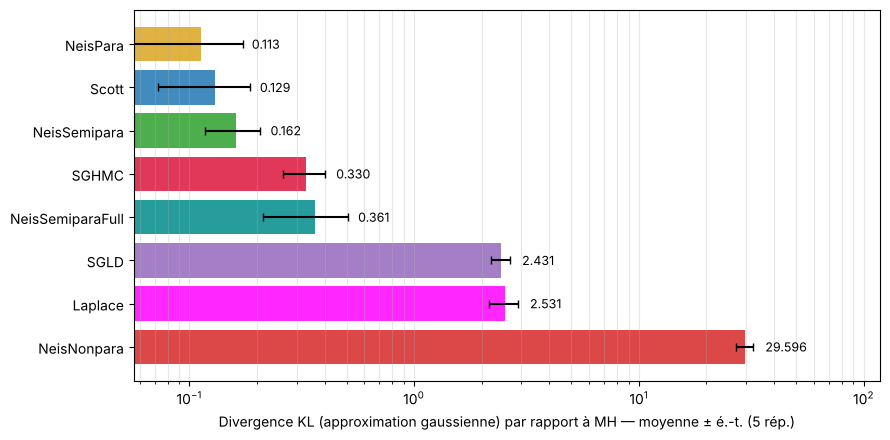

In [24]:
print("[5] Divergence KL (approximation gaussienne) : 5 répétitions indépendantes")
R_REP = 5


def all_methods(seed):
    """Relance toute la chaîne (partition, sous-lois, recombinaisons, SG, Laplace)."""
    r = np.random.default_rng(1000 + seed)
    ch = np.array_split(r.permutation(N_TRAIN), S_BATCH)
    bs = [mh_sub_posterior_logistic(X_tr[c], y_tr[c], M_SUB, S_BATCH, BURN_SUB, r) for c in ch]
    ms = max(b.std(axis=0).max() for b in bs)
    return {"Scott": consensus_scott(bs),
            "NeisPara": neiswanger_parametric(bs, rng=r),
            "NeisNonpara": neiswanger_nonparametric(bs, 1.2 * ms, True, rng=r),
            "NeisSemipara": neiswanger_semiparametric(bs, 2.0 * ms, True, rng=r),
            "NeisSemiparaFull": neiswanger_semiparametric_full(bs, 2.0 * ms, True, rng=r),
            "SGLD": sgld_logistic(X_tr, y_tr, SGLD_IT, SGLD_N, SGLD_A, r)[SGLD_BURN:],
            "SGHMC": sghmc_logistic(X_tr, y_tr, SGHMC_IT, SGHMC_N, SGHMC_A, SGHMC_G / N_TRAIN,
                                    SGHMC_L, r)[SGHMC_BURN:],
            "Laplace": stochastic_laplace_logistic(X_tr, y_tr, 20_000, r)[0]}


kl_rep = {m: [kl_gauss(samples[m], mh_ref)] for m in METHODS}
for rep in range(1, R_REP):
    s_rep = all_methods(rep)
    for m in METHODS:
        kl_rep[m].append(kl_gauss(s_rep[m], mh_ref))
kl = {m: float(np.mean(v)) for m, v in kl_rep.items()}
kl_sd = {m: float(np.std(v)) for m, v in kl_rep.items()}
# bruit de référence : un second MH indépendant, de même longueur, comparé à la référence
mh_check = mh_logistic(X_tr, y_tr, M_MH, BURN_MH, np.random.default_rng(2))
print(f"    plancher de bruit (second MH indépendant) : KL = {kl_gauss(mh_check, mh_ref):.3f}")

print(f"    {'méthode':18s} {'KL moy.':>8s} {'± é.-t.':>8s} {'max|Δμ|/σ':>10s} "
      f"{'σ/σ_MH min–max':>15s} {'τ':>6s}")
moments = {}
extra = {m: kl_gauss(samples[m], mh_ref) for m in ["Scott (diag.)", "NeisNonpara (std.)"]}
for m in sorted(METHODS, key=kl.get) + list(extra):
    dmu = np.abs(samples[m].mean(axis=0) - mh_ref.mean(axis=0)) / post_sd
    rsd = samples[m].std(axis=0) / post_sd
    tau = integrated_autocorr_time(samples[m])
    moments[m] = {"max_dmu": float(dmu.max()), "sd_min": float(rsd.min()),
                  "sd_max": float(rsd.max()), "tau": float(tau)}
    k_m, s_m = (kl[m], kl_sd[m]) if m in kl else (extra[m], float("nan"))
    print(f"    {m:18s} {k_m:8.3f} {s_m:8.3f} {dmu.max():10.2f} "
          f"{rsd.min():7.2f}–{rsd.max():.2f} {tau:6.0f}")
results["kl_gauss"] = {"moyenne": kl, "ecart_type": kl_sd, "repetitions": kl_rep,
                       "hors_classement": extra}
results["moments"] = moments

order = sorted(METHODS, key=lambda m: kl[m])
fig, ax = plt.subplots(figsize=(9, 4.5))
vals = [kl[m] for m in order]
ax.barh(range(len(order)), vals, xerr=[kl_sd[m] for m in order],
        color=[COLORS[m] for m in order], alpha=0.85, capsize=3)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("Divergence KL (approximation gaussienne) par rapport à MH — moyenne ± é.-t. (5 rép.)")
for i, v in enumerate(vals):
    ax.text(v * 1.15 + kl_sd[order[i]], i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(min(vals) / 2, max(vals) * 4)
ax.grid(True, axis="x", alpha=0.3, which="both")
fig.tight_layout()
fig.savefig(f"{OUT}/Fig_4_5.png", dpi=150)
plt.show()

## Figure 4.1 — Distributions marginales

[6] Figure 4.1 : distributions marginales


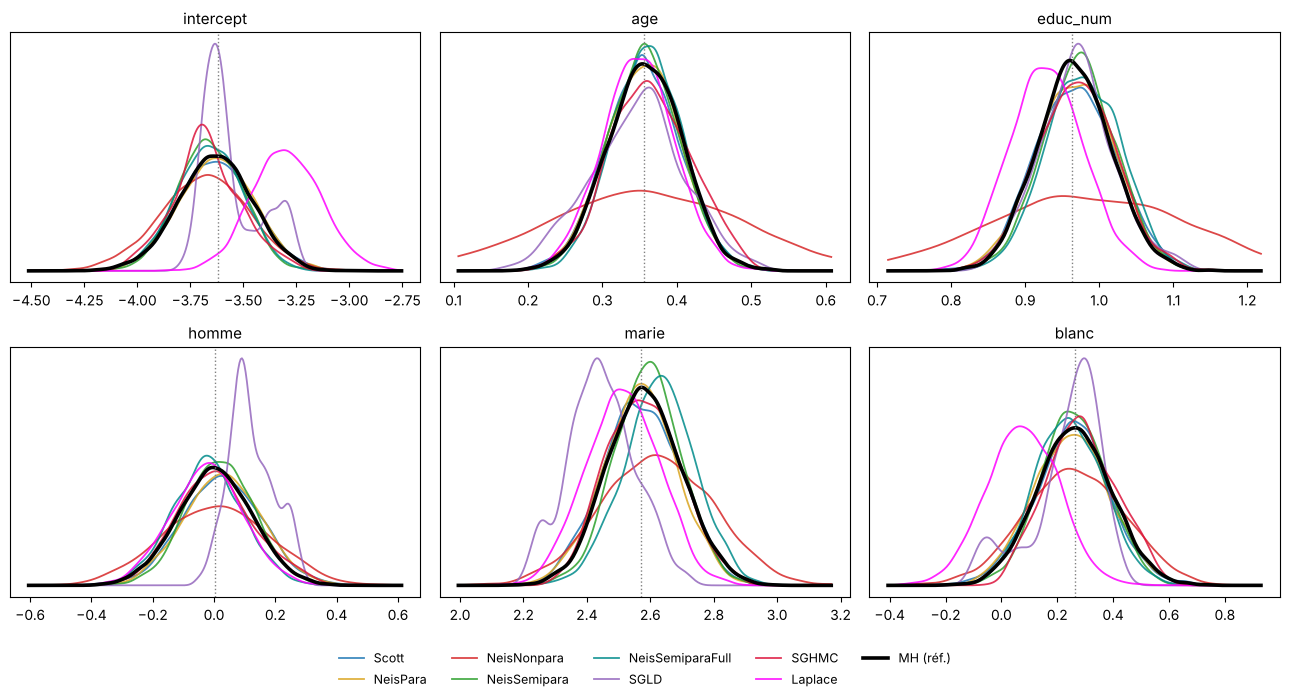

In [25]:
print("[6] Figure 4.1 : distributions marginales")
coef_show = [0, 1, 2, 6, 7, 9]           # intercept, age, educ_num, homme, marie, blanc
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, j in zip(axes.flat, coef_show):
    lo = mh_ref[:, j].mean() - 5 * post_sd[j]
    hi = mh_ref[:, j].mean() + 5 * post_sd[j]
    grid = np.linspace(lo, hi, 300)
    for m in METHODS:
        ax.plot(grid, gaussian_kde(samples[m][::5, j])(grid), color=COLORS[m], lw=1.3,
                alpha=0.85, label=m)
    ax.plot(grid, gaussian_kde(mh_ref[::20, j])(grid), color="black", lw=2.6, label="MH (réf.)")
    ax.axvline(theta_map[j], color="gray", ls=":", lw=1)
    ax.set_title(FEATURE_NAMES[j], fontsize=11)
    ax.set_yticks([])
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, fontsize=9, frameon=False)
fig.tight_layout(rect=[0, 0.08, 1, 1])
fig.savefig(f"{OUT}/Fig_4_1.png", dpi=150)
plt.show()

## Figure 4.2 — Vitesse de convergence

[7] Figure 4.2 : traces de convergence (coefficient « marie »)
    MH     premier passage =    821 it. équiv. (4,105,000 évaluations élémentaires) ; fraction stationnaire dans la bande = 0.952
    SGLD   premier passage =    909 it. équiv. (29,088 évaluations élémentaires) ; fraction stationnaire dans la bande = 0.863
    SGHMC  premier passage =   1650 it. équiv. (211,200 évaluations élémentaires) ; fraction stationnaire dans la bande = 0.961


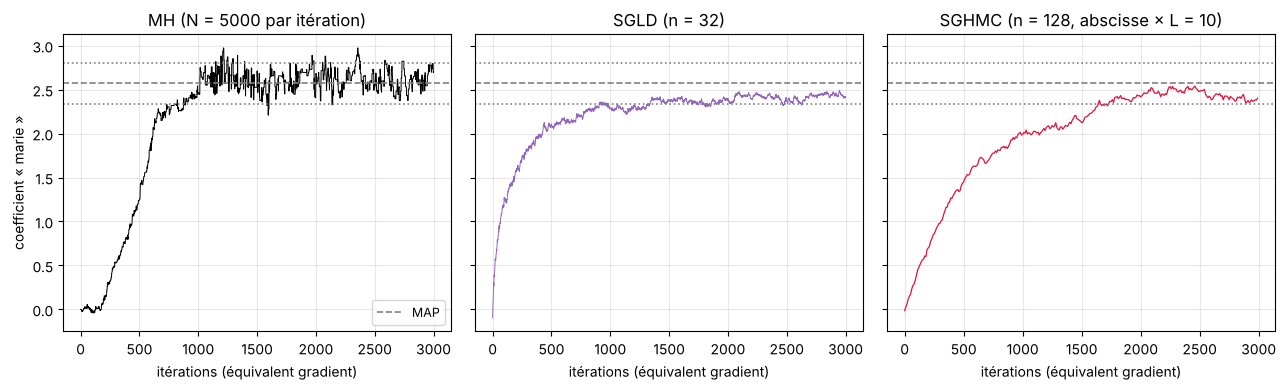

In [26]:
print("[7] Figure 4.2 : traces de convergence (coefficient « marie »)")
J = FEATURE_NAMES.index("marie")
band = 2 * post_sd[J]


def first_passage(trace, scale=1):
    """Première itération (en équivalents gradient) où la trace entre dans MAP ± 2σ_MH."""
    inside = np.abs(trace[:, J] - theta_map[J]) < band
    return (int(np.argmax(inside)) if inside.any() else len(inside)) * scale


conv = {"MH": first_passage(mh_full), "SGLD": first_passage(sgld_trace),
        "SGHMC": first_passage(sghmc_trace, SGHMC_L)}
frac_band = {m: float(np.mean(np.abs(samples.get(m, mh_ref)[:, J] - theta_map[J]) < band))
             for m in ["SGLD", "SGHMC"]}
frac_band["MH"] = float(np.mean(np.abs(mh_ref[:, J] - theta_map[J]) < band))
cost = {"MH": N_TRAIN, "SGLD": SGLD_N, "SGHMC": SGHMC_N}
for m, f_ in conv.items():
    print(f"    {m:6s} premier passage = {f_:6d} it. équiv. ({f_ * cost[m]:,} évaluations "
          f"élémentaires) ; fraction stationnaire dans la bande = {frac_band[m]:.3f}")
results["convergence"] = {m: {"premier_passage": v, "evaluations": v * cost[m],
                              "fraction_bande": frac_band[m]} for m, v in conv.items()}

n_show = 3000
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
axes[0].plot(mh_full[:n_show, J], color="black", lw=0.7)
axes[0].set_title("MH (N = 5000 par itération)")
axes[1].plot(sgld_trace[:n_show, J], color=COLORS["SGLD"], lw=0.7)
axes[1].set_title(f"SGLD (n = {SGLD_N})")
x_h = np.arange(len(sghmc_trace)) * SGHMC_L
mask = x_h < n_show
axes[2].plot(x_h[mask], sghmc_trace[mask, J], color=COLORS["SGHMC"], lw=0.9)
axes[2].set_title(f"SGHMC (n = {SGHMC_N}, abscisse × L = {SGHMC_L})")
for ax in axes:
    ax.axhline(theta_map[J], color="gray", ls="--", lw=1.2, label="MAP")
    for b in (-band, band):
        ax.axhline(theta_map[J] + b, color="gray", ls=":", lw=1.2)   # limites MAP ± 2σ (sans ombre)
    ax.set_xlabel("itérations (équivalent gradient)")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("coefficient « marie »")
axes[0].legend(fontsize=9)
fig.tight_layout()
fig.savefig(f"{OUT}/Fig_4_2.png", dpi=150)
plt.show()

## Figure 4.3 — Performance prédictive

[8] Figure 4.3 : performance prédictive


    MH                 accuracy = 0.8362  log-loss = 0.3471  AUC = 0.8871
    Scott              accuracy = 0.8362  log-loss = 0.3470  AUC = 0.8872
    NeisPara           accuracy = 0.8362  log-loss = 0.3470  AUC = 0.8872
    NeisNonpara        accuracy = 0.8363  log-loss = 0.3469  AUC = 0.8870
    NeisSemipara       accuracy = 0.8363  log-loss = 0.3471  AUC = 0.8871
    NeisSemiparaFull   accuracy = 0.8369  log-loss = 0.3473  AUC = 0.8870
    SGLD               accuracy = 0.8368  log-loss = 0.3468  AUC = 0.8873
    SGHMC              accuracy = 0.8366  log-loss = 0.3470  AUC = 0.8872
    Laplace            accuracy = 0.8366  log-loss = 0.3475  AUC = 0.8870
    MAP                accuracy = 0.8362  log-loss = 0.3471  AUC = 0.8871


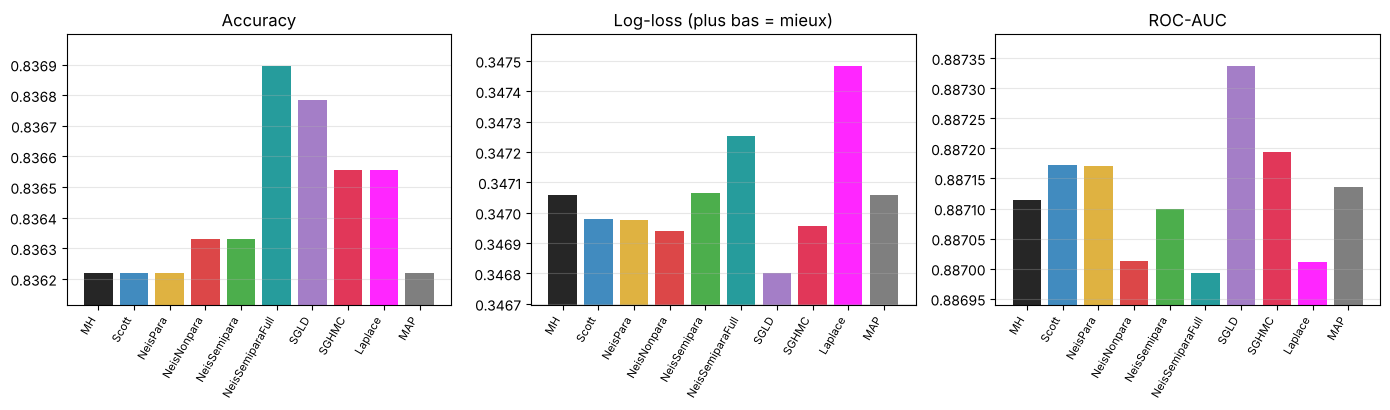

In [27]:
print("[8] Figure 4.3 : performance prédictive")
pred = {"MH": predictive_metrics(mh_ref, X_test, y_test)}
for m in METHODS:
    pred[m] = predictive_metrics(samples[m], X_test, y_test)
pred["MAP"] = point_metrics(theta_map, X_test, y_test)
for m, p in pred.items():
    print(f"    {m:18s} accuracy = {p['accuracy']:.4f}  log-loss = {p['logloss']:.4f}  "
          f"AUC = {p['auc']:.4f}")
results["predictive"] = pred

names = list(pred)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, key, title in zip(axes, ["accuracy", "logloss", "auc"],
                          ["Accuracy", "Log-loss (plus bas = mieux)", "ROC-AUC"]):
    v = [pred[m][key] for m in names]
    ax.bar(range(len(names)), v, color=[COLORS.get(m, "dimgray") for m in names], alpha=0.85)
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(names, rotation=60, ha="right", fontsize=8)
    ax.set_title(title)
    lo, hi = min(v), max(v)
    pad = 0.15 * (hi - lo) if hi > lo else 0.01
    ax.set_ylim(lo - pad, hi + pad)
    ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(f"{OUT}/Fig_4_3.png", dpi=150)
plt.show()

## Figure 4.4 — Passage à l'échelle

[9] Figure 4.4 : passage à l'échelle (500 échantillons, burn-in 100)


    N =    500 : MH = 6.7 ms  Scott = 8.3 ms  SGLD = 0.5 ms  SGHMC = 14.8 ms


    N =   2000 : MH = 26.5 ms  Scott = 27.2 ms  SGLD = 0.5 ms  SGHMC = 15.6 ms


    N =   5000 : MH = 66.4 ms  Scott = 64.5 ms  SGLD = 0.5 ms  SGHMC = 16.8 ms


    N =  15000 : MH = 210.8 ms  Scott = 199.9 ms  SGLD = 1.1 ms  SGHMC = 17.8 ms


    N =  40000 : MH = 578.5 ms  Scott = 581.0 ms  SGLD = 1.1 ms  SGHMC = 33.1 ms
    pente log-log MH     = 1.02
    pente log-log Scott  = 0.97
    pente log-log SGLD   = 0.21
    pente log-log SGHMC  = 0.16
    à N = 40000 : SGLD ×515 plus rapide que MH, SGHMC ×17


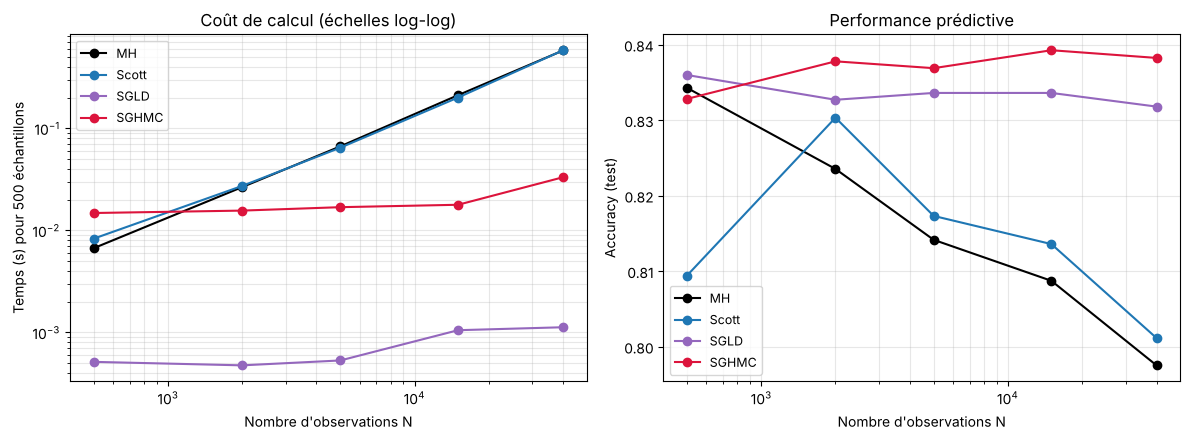

In [28]:
print("[9] Figure 4.4 : passage à l'échelle (500 échantillons, burn-in 100)")
N_SCALE = [500, 2000, 5000, 15000, 40000]
M_SC, B_SC, REPEATS = 500, 100, 3
scale_res = {m: {"time": [], "acc": []} for m in ["MH", "Scott", "SGLD", "SGHMC"]}


def best_time(fn):
    best, out = np.inf, None
    for _ in range(REPEATS):
        t0 = time.time()
        out = fn()
        best = min(best, time.time() - t0)
    return out, best


def scott_run(Xn, yn, r):
    ch = np.array_split(r.permutation(Xn.shape[0]), S_BATCH)
    return consensus_scott([mh_sub_posterior_logistic(Xn[c], yn[c], M_SC, S_BATCH, B_SC, r)
                            for c in ch])


for N in N_SCALE:
    Xn, yn = X_pool[:N], y_pool[:N]
    runs = {
        "MH": lambda: mh_logistic(Xn, yn, M_SC, B_SC, np.random.default_rng(N)),
        "Scott": lambda: scott_run(Xn, yn, np.random.default_rng(N)),
        "SGLD": lambda: sgld_logistic(Xn, yn, M_SC + B_SC, SGLD_N, SGLD_A,
                                      np.random.default_rng(N))[B_SC:],
        "SGHMC": lambda: sghmc_logistic(Xn, yn, M_SC + B_SC, min(SGHMC_N, N), SGHMC_A,
                                        SGHMC_G / N, SGHMC_L, np.random.default_rng(N))[B_SC:],
    }
    for m, fn in runs.items():
        s, t = best_time(fn)
        scale_res[m]["time"].append(t)
        scale_res[m]["acc"].append(predictive_metrics(s, X_test, y_test)["accuracy"])
    print(f"    N = {N:6d} : " + "  ".join(f"{m} = {scale_res[m]['time'][-1] * 1000:.1f} ms"
                                           for m in scale_res))
for m in scale_res:
    slope = np.polyfit(np.log(N_SCALE), np.log(scale_res[m]["time"]), 1)[0]
    print(f"    pente log-log {m:6s} = {slope:.2f}")
speed_sgld = scale_res["MH"]["time"][-1] / scale_res["SGLD"]["time"][-1]
speed_sghmc = scale_res["MH"]["time"][-1] / scale_res["SGHMC"]["time"][-1]
print(f"    à N = {N_SCALE[-1]} : SGLD ×{speed_sgld:.0f} plus rapide que MH, SGHMC ×{speed_sghmc:.0f}")
results["scaling"] = {"N": N_SCALE, **scale_res, "speedup_sgld": speed_sgld,
                      "speedup_sghmc": speed_sghmc}

sc_col = {"MH": "black", "Scott": "tab:blue", "SGLD": "tab:purple", "SGHMC": "crimson"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for m in scale_res:
    axes[0].loglog(N_SCALE, scale_res[m]["time"], marker="o", color=sc_col[m], label=m)
    axes[1].semilogx(N_SCALE, scale_res[m]["acc"], marker="o", color=sc_col[m], label=m)
axes[0].set_xlabel("Nombre d'observations N")
axes[0].set_ylabel("Temps (s) pour 500 échantillons")
axes[0].set_title("Coût de calcul (échelles log-log)")
axes[1].set_xlabel("Nombre d'observations N")
axes[1].set_ylabel("Accuracy (test)")
axes[1].set_title("Performance prédictive")
for ax in axes:
    ax.grid(True, alpha=0.3, which="both")
    ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(f"{OUT}/Fig_4_4.png", dpi=150)
plt.show()

## Sauvegarde des résultats

In [29]:
results["timings_N5000"] = timings
results["protocol"] = {"M_MH": M_MH, "BURN_MH": BURN_MH, "S": S_BATCH, "M_SUB": M_SUB,
                       "BURN_SUB": BURN_SUB, "tau": TAU,
                       "SGLD": {"a": SGLD_A, "n": SGLD_N, "iters": SGLD_IT, "burn": SGLD_BURN},
                       "SGHMC": {"gamma": SGHMC_G, "alpha": SGHMC_A, "n": SGHMC_N,
                                 "L": SGHMC_L, "iters": SGHMC_IT, "burn": SGHMC_BURN}}
with open(f"{OUT}/results_chapitre4.json", "w") as f:
    json.dump(results, f, indent=2, default=float)
print(f"Terminé en {time.time() - t_start:.0f} s")

Terminé en 83 s
